# Week 2 — Exploratory Data Analysis: NextGenLearners Applicant Insights

In this notebook, I will explore the cleaned applicant dataset, identify patterns, analyze application trends, and communicate the findings through clear visualizations.

**Goal:** Ask a question, answer it with Pandas, visualize the result, and write a short takeaway after each chart.

## Step 1 — Load the cleaned dataset

The CSV stores dates as text, so `parse_dates=['Application Date']` tells Pandas to load the application dates as datetime values.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('applicants_cleaned.csv', parse_dates=['Application Date'])

## Step 1A — Sanity check

Check the dataset structure, first rows, missing values, and date range before starting the analysis.

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 485 entries, 0 to 484
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    485 non-null    object        
 1   Email             485 non-null    object        
 2   Phone             474 non-null    float64       
 3   Domain Applied    485 non-null    object        
 4   University        485 non-null    object        
 5   Application Date  478 non-null    datetime64[ns]
 6   Status            485 non-null    object        
dtypes: datetime64[ns](1), float64(1), object(5)
memory usage: 26.7+ KB


In [3]:
df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Noor Baig,noor.baig781@yahoo.com,3.619049e+09,Data Science,LUMS,2026-06-04,Selected
1,Hassan Siddiqui,hassan.siddiqui151@yahoo.com,3.117406e+09,Web Development,GIKI,2026-06-11,Selected
2,Faisal Ali,faisal.ali578@yahoo.com,3.516569e+09,Web Development,NUST,2026-05-03,Rejected
3,Saad Akhtar,saad.akhtar886@gmail.com,3.348879e+09,Machine Learning,LUMS,2026-04-27,Under Review
4,Komal Mirza,komal.mirza578@gmail.com,3.507670e+09,UI/UX Design,LUMS,2026-12-04,Rejected


In [4]:
print("Dataset shape:", df.shape)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nApplication date range:")
print(df['Application Date'].min())
print(df['Application Date'].max())

Dataset shape: (485, 7)

Missing values in each column:
Applicant Name       0
Email                0
Phone               11
Domain Applied       0
University           0
Application Date     7
Status               0
dtype: int64

Application date range:
2026-01-01 00:00:00
2026-12-06 00:00:00


## Step 2 — What does EDA mean?

Exploratory Data Analysis (EDA) means exploring a dataset with summary statistics and charts before drawing conclusions or building a model.

For each question below, I will:
1. Calculate the relevant numbers.
2. Create a chart with a clear title and labeled axes.
3. Add a short takeaway immediately after the chart.

## Step 3 — Which domain received the most applications?

First, count applications in each domain using `value_counts()`.

In [5]:
domain_counts = df['Domain Applied'].value_counts()
print(domain_counts)

Domain Applied
Machine Learning     105
UI/UX Design         103
Web Development       99
Digital Marketing     92
Data Science          86
Name: count, dtype: int64


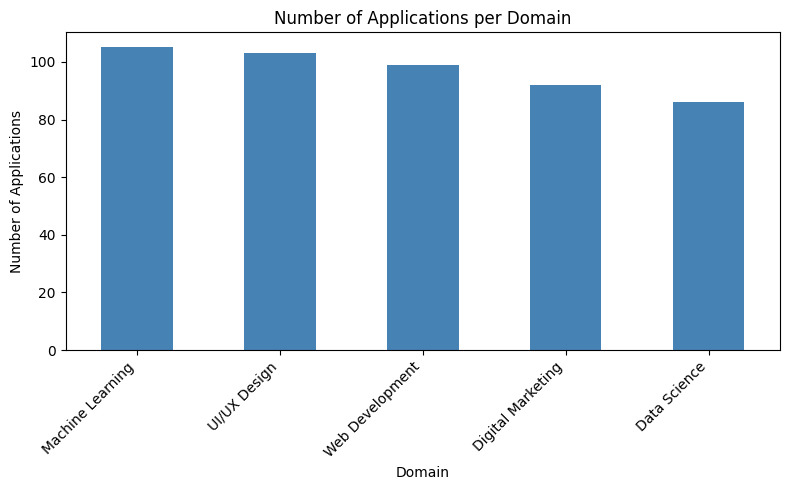

In [6]:
plt.figure(figsize=(8, 5))
domain_counts.plot(kind='bar', color='steelblue')

plt.title('Number of Applications per Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Takeaway:** Machine Learning received the highest number of applications (105), while Data Science received the lowest (86), a difference of 19 applications. These figures should be checked against the chart if the dataset is updated.

## Step 4 — How did applications trend over time?

Group application dates by month, then count applications in each month.

In [7]:
df['Application Month'] = df['Application Date'].dt.to_period('M')
monthly_trend = df.groupby('Application Month').size()
print(monthly_trend)

Application Month
2026-01    81
2026-02    65
2026-03    74
2026-04    80
2026-05    65
2026-06    89
2026-07     1
2026-08     3
2026-09     2
2026-10     7
2026-11     2
2026-12     9
Freq: M, dtype: int64


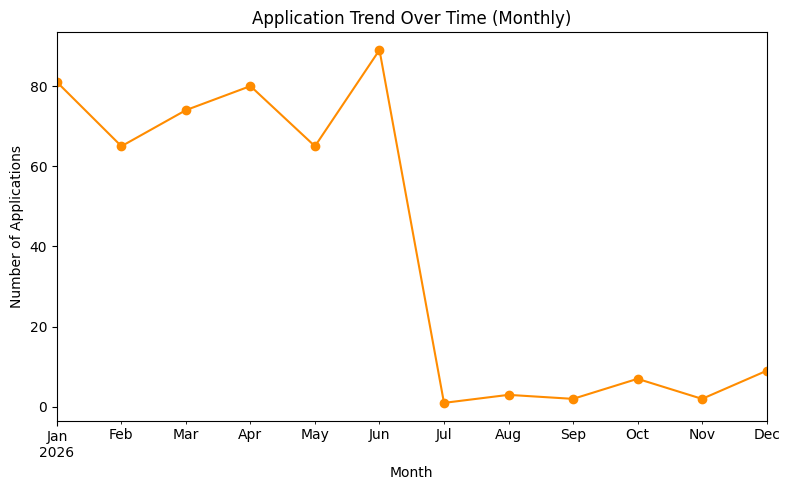

In [8]:
plt.figure(figsize=(8, 5))
monthly_trend.plot(kind='line', marker='o', color='darkorange')

plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.tight_layout()
plt.show()

**Takeaway:** Applications peaked in June 2026 with 89 applications. Counts were much lower from July onward, so the later-month trend should be interpreted cautiously and verified before drawing conclusions.

## Step 5 — What is the overall application-status breakdown?

Use `value_counts()` to count the applications in each status.

In [9]:
status_counts = df['Status'].value_counts()
print(status_counts)

Status
Under Review    175
Rejected        166
Selected        144
Name: count, dtype: int64


### Overall status breakdown — pie chart

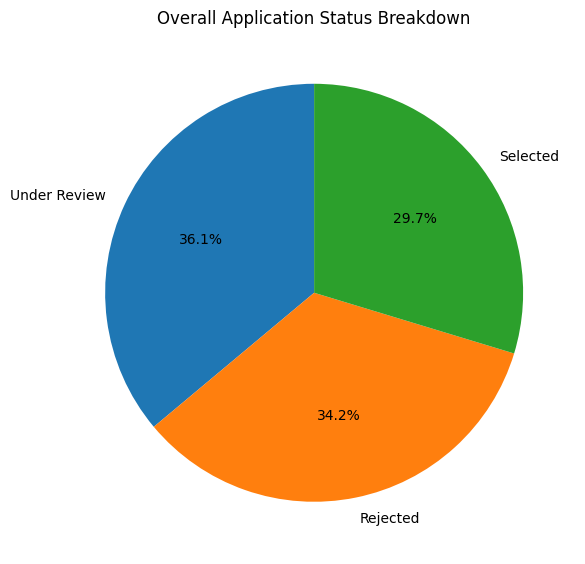

In [10]:
plt.figure(figsize=(6, 6))
status_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90)

plt.title('Overall Application Status Breakdown')
plt.ylabel('')
plt.tight_layout()
plt.show()

**Takeaway:** Out of 485 applicants, 175 are under review, 166 have been rejected, and 144 have been selected. Under Review is the largest status category.

### Status by domain — pivot table

A pivot table creates a grid with one row per domain and one column per status. `fill_value=0` displays zero where a domain has no applicants in a status.

In [11]:
status_by_domain = pd.pivot_table(
    df,
    index='Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
)

print(status_by_domain)

Status             Rejected  Selected  Under Review
Domain Applied                                     
Data Science             28        30            28
Digital Marketing        28        24            40
Machine Learning         38        27            40
UI/UX Design             36        36            31
Web Development          36        27            36


### Status percentages by domain

Percentages make it easier to compare domains with different numbers of applicants. These percentages show each status's share of all applicants in that domain; because Under Review cases are included, the Selected percentage is not necessarily a final acceptance rate.

In [12]:
status_by_domain_pct = (
    status_by_domain.div(status_by_domain.sum(axis=1), axis=0) * 100
)
print(status_by_domain_pct.round(1))

Status             Rejected  Selected  Under Review
Domain Applied                                     
Data Science           32.6      34.9          32.6
Digital Marketing      30.4      26.1          43.5
Machine Learning       36.2      25.7          38.1
UI/UX Design           35.0      35.0          30.1
Web Development        36.4      27.3          36.4


### Application status by domain — grouped bar chart

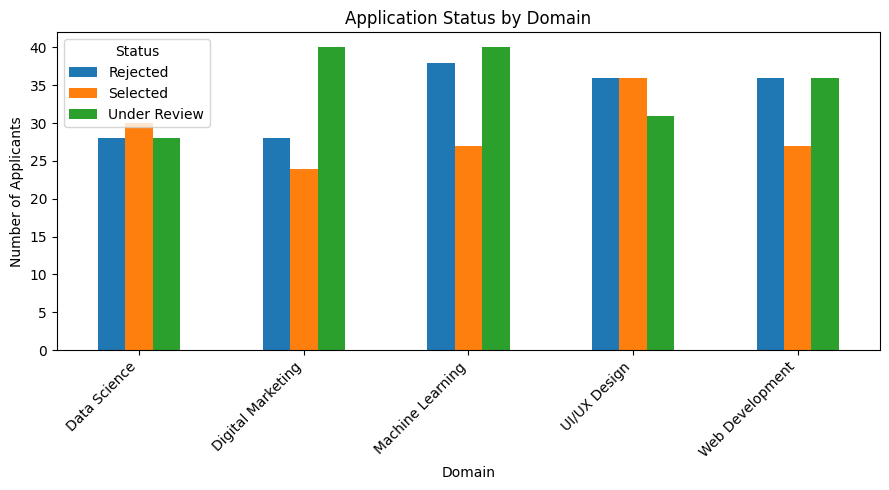

In [13]:
status_by_domain.plot(kind='bar', figsize=(9, 5))

plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')
plt.tight_layout()
plt.show()

**Takeaway:** Data Science has the highest current selected share at 34.9%, while Machine Learning has the lowest at 25.7%. These percentages include applicants who are still under review, so they should not be treated as final acceptance rates.

## Step 6 — Which universities sent the most applicants?

Use `value_counts()` and keep only the top 10 universities so the chart remains readable.

In [14]:
top_universities = df['University'].value_counts().head(10)
print(top_universities)

University
UET Lahore                  56
Air University              54
LUMS                        52
IBA Karachi                 52
University of Karachi       48
FAST-NUCES                  46
COMSATS University          40
NUST                        38
GIKI                        38
University of the Punjab    37
Name: count, dtype: int64


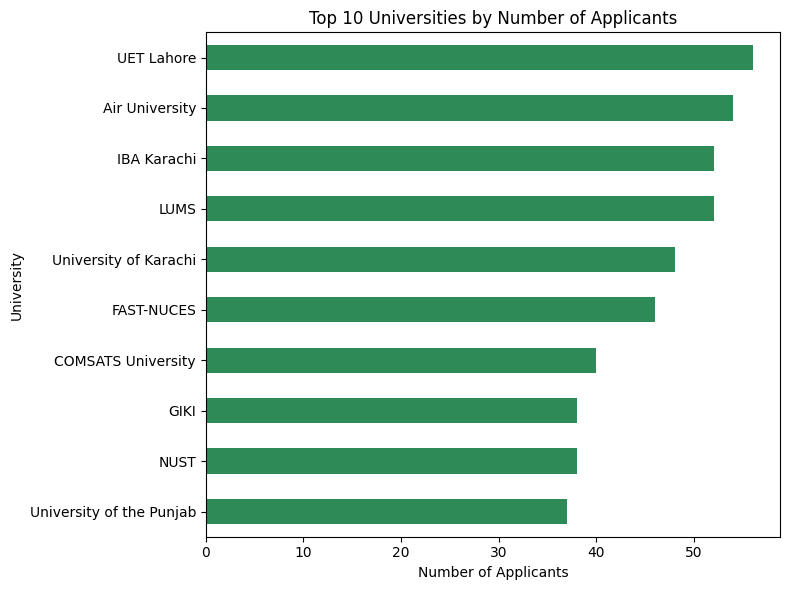

In [15]:
plt.figure(figsize=(8, 6))
top_universities.sort_values().plot(kind='barh', color='seagreen')

plt.title('Top 10 Universities by Number of Applicants')
plt.xlabel('Number of Applicants')
plt.ylabel('University')
plt.tight_layout()
plt.show()

**Takeaway:** UET Lahore contributed the highest number of applicants (56), followed by Air University (54). LUMS and IBA Karachi each contributed 52 applicants.

## Step 7 — Bonus question: Do some days of the week receive more applications?

I chose this question to explore whether applications are distributed evenly across weekdays or whether certain days receive more applications.

In [16]:
df['Day of Week'] = df['Application Date'].dt.day_name()

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

weekday_counts = df['Day of Week'].value_counts().reindex(
    weekday_order, fill_value=0
)
print(weekday_counts)

Day of Week
Monday       67
Tuesday      62
Wednesday    63
Thursday     70
Friday       62
Saturday     79
Sunday       75
Name: count, dtype: int64


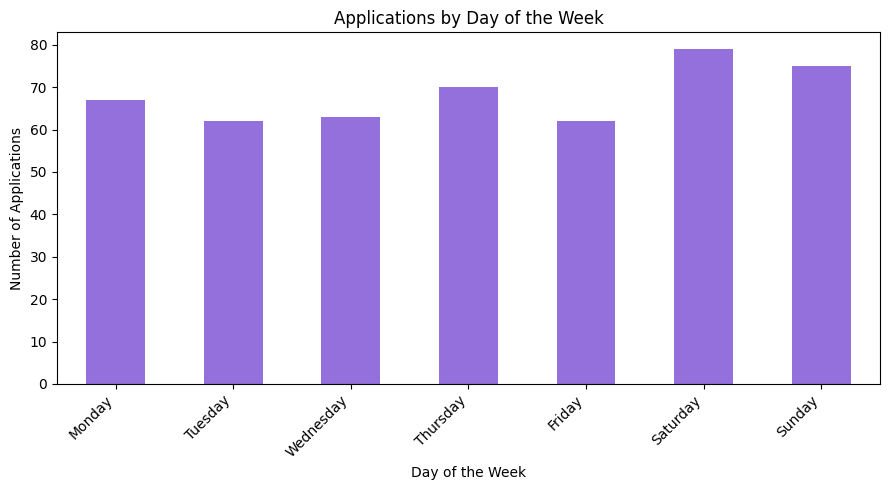

In [17]:
plt.figure(figsize=(9, 5))
weekday_counts.plot(kind='bar', color='mediumpurple')

plt.title('Applications by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Takeaway:** Saturday received the highest number of applications (79), while Tuesday and Friday received the lowest (62 each). Weekend applications were relatively high, although this pattern alone does not explain why applicants chose those days.

## Step 8 — Key Insights

- **Domain popularity:** Machine Learning received the highest number of applications (105), while Data Science received the lowest (86).
- **Application timing:** Applications peaked in June 2026 with 89 applications. Counts dropped sharply from July onward, so later-month data should be verified before drawing conclusions.
- **Current application status:** Out of 485 applicants, 144 were selected, 166 were rejected, and 175 remain under review.
- **Status by domain:** Data Science had the highest current selection percentage (34.9%), while Machine Learning had the lowest (25.7%). These are not final acceptance rates because some applications remain under review.
- **University and weekday patterns:** UET Lahore contributed the most applicants (56), and Saturday had the highest number of applications by weekday (79).

These findings can help the program team understand application volume and status distribution. They describe patterns in this dataset and do not, by themselves, establish why those patterns occurred.